<div class="alert alert-info" role="alert"
     style="font-size: 1.55em; font-weight: bold; padding: 15px; margin: 10px 0; text-align: left; background-color: #d9edf7; border-color: #bce8f1; color: #31708f; border-radius: 8px;">
    OCA vs CLARA:  weekly May-August cloud fraction where the records overlap
</div>

### Basic set up ▶▶ Libraries and helper functions

In [1]:
import xarray as xr
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import regionmask

In [2]:
fm.fontManager.addfont("/home/nandii/cloudf/Roboto-Regular.ttf")
fm.fontManager.addfont("/home/nandii/cloudf/Roboto-Bold.ttf")
plt.rcParams["font.weight"] = "normal"
plt.rcParams["axes.titleweight"] = "bold"

In [3]:
# Land-masked, May-Aug, box-mean daily series from a set of zarr stores
def bloom_series(paths, var):
    # Box trimmed to 60W-20W
    ds = xr.concat([xr.open_zarr(p)[[var]] for p in paths], dim = "time").sortby("time").sel(lon = slice(-60, -20))
    land = regionmask.defined_regions.natural_earth_v5_0_0.land_110.mask(ds.lon, ds.lat)
    cf = ds[var].where(np.isnan(land))
    cf = cf.sel(time = cf.time.dt.month.isin(bloom_months)).mean(dim = ["lat", "lon"]).compute()
    return pd.Series(cf.values, index = pd.DatetimeIndex(cf.time.values)).dropna()

### Load data ▶▶ daily series, matched days, weekly means

In [4]:
bloom_months = [5, 6, 7, 8]

clara = bloom_series(["/home/nandii/cloudf/cfc_subset_1991_2010.zarr",
                      "/home/nandii/cloudf/cfc_subset_2011_2026.zarr"], "cfc")
oca   = bloom_series(["/home/nandii/cloudML/OCA_sectors_ss_2004_2010.zarr",
                      "/home/nandii/cloudML/OCA_sectors_ss_2011_2019.zarr"], "cf_scene")

# Only days present in both records, so each weekly mean is built from the same days
daily = pd.DataFrame({"CLARA": clara, "OCA": oca}).dropna()
weekly = daily.resample("W").mean().dropna()
weekly["diff"] = weekly["OCA"] - weekly["CLARA"]

print(f"Matched days : {len(daily)}, {daily.index.min().date()} to {daily.index.max().date()}")
print(f"Weekly means : {len(weekly)}")

Matched days : 1960, 2004-05-01 to 2019-08-31
Weekly means : 295


### Statistics ▶▶ OCA minus CLARA, full overlap and pre-/post-2011

In [5]:
split = pd.Timestamp("2011-01-01")

stats = {}
for block, w in [("Full", weekly), ("Pre-2011", weekly[weekly.index < split]), ("Post-2011", weekly[weekly.index >= split])]:
    stats[block] = {"n_weeks": len(w),
                    "CLARA_mean": w["CLARA"].mean(), "OCA_mean": w["OCA"].mean(),
                    "mean_diff_pp": w["diff"].mean(), "sd_diff_pp": w["diff"].std(),
                    "rmsd_pp": np.sqrt((w["diff"] ** 2).mean()),
                    "pearson_r": w["OCA"].corr(w["CLARA"]),
                    "CLARA_sd": w["CLARA"].std(), "OCA_sd": w["OCA"].std()}

pd.DataFrame(stats).T.round(2)

,n_weeks,CLARA_mean,OCA_mean,mean_diff_pp,sd_diff_pp,rmsd_pp,pearson_r,CLARA_sd,OCA_sd
Full,295.0,57.77,61.91,4.14,2.78,4.98,0.90,6.24,5.60
Pre-2011,130.0,57.95,61.98,4.03,2.63,4.80,0.91,6.32,5.69
Post-2011,165.0,57.62,61.85,4.23,2.90,5.12,0.88,6.19,5.54


In [6]:
# Mean weekly difference per season
yearly = weekly.groupby(weekly.index.year).agg(CLARA = ("CLARA", "mean"), OCA = ("OCA", "mean"),
                                               mean_diff_pp = ("diff", "mean"), pearson_r = ("CLARA", lambda c: c.corr(weekly.loc[c.index, "OCA"])))
yearly.round(2)

,CLARA,OCA,mean_diff_pp,pearson_r
2004,54.55,59.520000,4.96,0.94
2005,57.19,60.860001,3.67,0.86
2006,58.96,62.779999,3.81,0.95
2007,58.20,62.320000,4.12,0.81
2008,58.37,61.779999,3.41,0.91
2009,56.98,61.450001,4.46,0.93
2010,61.51,65.199997,3.69,0.88
2011,57.02,62.619999,5.59,0.96
2012,55.98,59.650002,3.68,0.89
2013,56.56,61.830002,5.27,0.94


### Plots ▶▶ weekly series and their difference over time

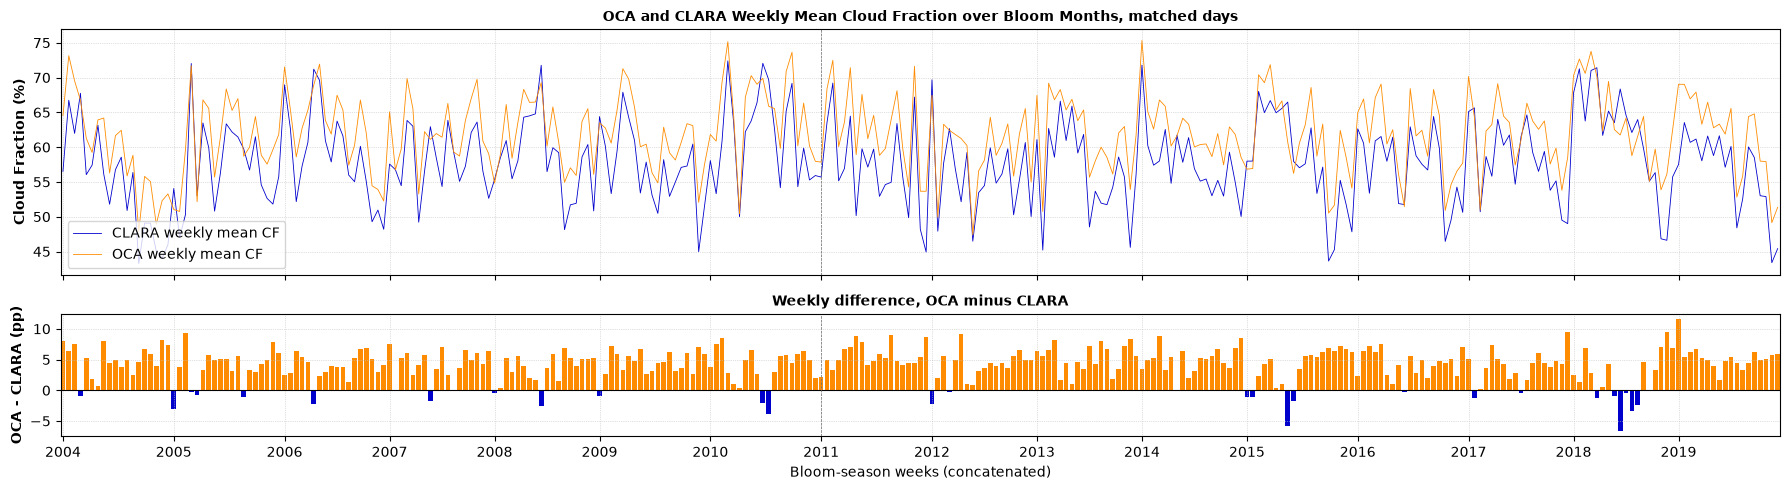

In [7]:
# Concatenated May-Aug axis, one step per week
seq = pd.Series(range(len(weekly)), index = weekly.index)
onset = seq[seq.index >= split].iloc[0]
first_weeks = seq.groupby(seq.index.year).min()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize = (18, 5), sharex = True, gridspec_kw = dict(height_ratios = [2, 1]))

ax1.plot(seq.values, weekly["CLARA"], linewidth = 0.6, color = 'mediumblue', label = 'CLARA weekly mean CF')
ax1.plot(seq.values, weekly["OCA"], linewidth = 0.6, color = 'darkorange', label = 'OCA weekly mean CF')
ax1.set_ylabel('Cloud Fraction (%)', fontsize = 10, weight = 'bold')
ax1.set_title('OCA and CLARA Weekly Mean Cloud Fraction over Bloom Months, matched days', fontsize = 10, weight = 'bold')
ax1.legend(loc = 'lower left')

ax2.bar(seq.values, weekly["diff"], width = 0.8, color = np.where(weekly["diff"] >= 0, 'darkorange', 'mediumblue'))
#for block, w, colour in [("Pre-2011", weekly[weekly.index < split], 'darkred'), ("Post-2011", weekly[weekly.index >= split], 'red')]:
    #ax2.hlines(w["diff"].mean(), seq[w.index].min(), seq[w.index].max(), color = colour, linewidth = 2.0,
               #label = f"{block} mean: {w['diff'].mean():+.2f} pp")
ax2.axhline(0, color = 'black', linewidth = 0.8)
ax2.set_ylabel('OCA - CLARA (pp)', fontsize = 10, weight = 'bold')
ax2.set_title('Weekly difference, OCA minus CLARA', fontsize = 10, weight = 'bold')
#ax2.legend(loc = 'lower left')

for ax in (ax1, ax2):
    ax.axvline(onset, color = 'dimgrey', linestyle = '--', linewidth = 0.5)
    ax.grid(True, color = 'silver', linestyle = ':', linewidth = 0.5)
    ax.margins(x = 0)
ax2.set_xticks(first_weeks.values)
ax2.set_xticklabels(first_weeks.index)
ax2.set_xlabel('Bloom-season weeks (concatenated)', fontsize = 10)
plt.tight_layout()
plt.show()

In [8]:
fig.savefig('OCA_CLARA_weekly_differences.png', dpi = 300, bbox_inches = 'tight')

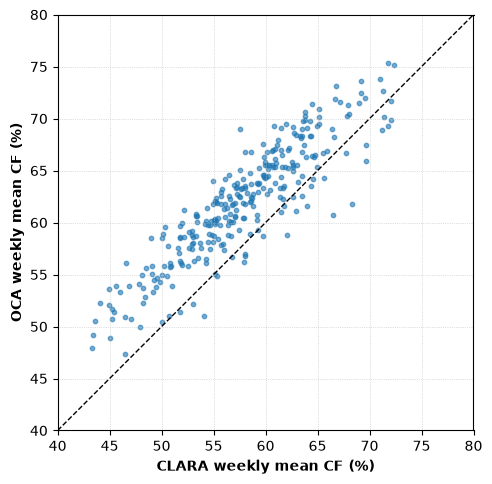

In [9]:
fig, ax = plt.subplots(figsize = (5, 5))

ax.scatter(weekly["CLARA"], weekly["OCA"], s = 10, alpha = 0.6)
lims = [40,80]
ax.plot(lims, lims, color = 'black', linestyle = '--', linewidth = 1)
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_aspect('equal')
ax.set_xlabel('CLARA weekly mean CF (%)', fontsize = 10, weight = 'bold')
ax.set_ylabel('OCA weekly mean CF (%)', fontsize = 10, weight = 'bold')
#ax.set_title('OCA vs CLARA, weekly means', fontsize = 10, weight = 'bold')
ax.grid(True, color = 'silver', linestyle = ':', linewidth = 0.5)

plt.tight_layout()
plt.show()

In [10]:
fig.savefig('OCA_CLARA_weekly_scatter.png', dpi = 300, bbox_inches = 'tight')